# Public Domain Opportunity Radar: Wanted, Out-of-Print Books That Become Free in the US and the Philippines in 2027

## 1 Executive Summary

Which books become free to republish in the United States or the Philippines on 1 January 2027, and which of them do readers want but publishers have not recently reissued? To answer this, the report screens the full Open Library catalogue (Open Library, 2026), which held 41.7 million works and 56.9 million editions on 31 October 2026, under the publication-based terms of the **United States** and the author's life plus 50 years used in the **Philippines**. It then sets those estimates against reader demand (13.2 million reading-log entries and 1.07 million ratings) and current supply (recent editions, publishers, scans and Filipino-language editions), with every step run in PySpark and the cleaned tables saved as Parquet.

**Main findings**

- **6.06 million works (14.5%) are potentially public domain** under at least one of the two rules. Of these, **1.51 million are free only under the Philippine rule**, confirming that life + 50 releases many 20th-century works decades before the US does, as seen in *Think and Grow Rich*, *How to Win Friends and Influence People*, *The Hobbit* and *Animal Farm*.
- **96,544 works enter the public domain on 1 January 2027**, made up of 71,520 first published in 1931 (US), 24,888 whose last author died in 1976 (Philippines) and 136 that qualify under both rules. The Philippine group is dominated by **Agatha Christie**, who died in 1976 and whose 1,012 catalogued works carry 22,008 Want-to-Read entries, or 52% of all demand among 2027 entrants, yet **none of them has a Filipino-language edition**.
- Older works are shelved less often than newer ones, with only 3.5% of US public-domain works carrying any Want-to-Read entry against 8.1% of post-1978 works, but readers who do shelve them rate them just as highly (close to 4.0 stars in every rights group). Their demand has also held up better, since Want-to-Read entries over the most recent 12 months fell by only 5.7% for public-domain works against 31.7% for post-1978 works, lifting their share of all demand from 5.1% to 6.7%.
- Supply is thin and almost entirely non-Filipino: only 1.8% of US public-domain works have an edition from 2017 onwards, while just 4,252 of the 41.7 million works (0.01%) have any edition in Tagalog or Filipino.
- The **2027 watchlist** keeps 53 works that have at least 33 Want-to-Read entries, which places them in the top 1% of shelved works, and no more than one edition since 2017. *Joy of Cooking* (1931 text) leads the list, followed by Josef Albers's *Interaction of Colour* and Dalton Trumbo's *Johnny Got His Gun*.

**How far to trust these lists.** A hand check of the 30 top-ranked rows found the estimated status correct for 28 of them, and both errors came from catalogue years: *Light in August* is dated 1931 although it was published in 1932, while *Cours de linguistique générale* is dated 1931 although it first appeared in 1916. The wider data are thinner than this sample suggests, because only 3.7% of authors have a known death year, leaving 84% of works unclassifiable under the Philippine rule, and some author links are wrong, as seen in a modern Robert Greene title that inherits the death year (1592) of the Elizabethan dramatist. Every list should therefore be read as a **shortlist for verification, not legal advice**, even though all ten independent recounts of the published totals matched.

**Recommendation.** A Philippine publisher should start with the Agatha Christie catalogue, which becomes free in the Philippines on 1 January 2027 with strong demand and no Filipino editions, and should confirm every watchlist row against a first-edition record and the author's death date before committing to a title. Matching the 3.0 million works first published in 1932-1963 against US renewal records would be the most valuable next step, since it would turn the largest uncertain group into firm answers.

## 2 Introduction

**Problem statement.** Which books become free to republish in the United States or the Philippines on 1 January 2027, and which of those do readers want but publishers have not recently reissued?

**Motivation.** When a book enters the public domain, anyone may reprint, translate, adapt or digitize it without asking permission or paying royalties, which gives publishers a recurring and predictable opportunity because a new group of works becomes free every 1 January (U.S. Copyright Office, n.d.). On **1 January 2027** the United States will release books first published in **1931** (Hirtle, 2026), whereas the Philippines bases its term on the author's life, protecting a work for the author's life plus **50 years** (Intellectual Property Code of the Philippines, 1997). Works by authors who died in **1976** therefore become free in the Philippines on the same day, and some books still protected in the United States or Europe may already be free there.

The question matters most to Philippine publishers, since the life-based rule can free a world classic years before it is free in the United States, and a Filipino translation of a wanted book that nobody has reissued is exactly the kind of opening a small press could act on. Finding such openings is still largely manual, though, because an editor has to check when a book first appeared, when every author died, whether readers still want it and whether other publishers already keep it in print. This project automates that first screening step using the monthly bulk data published by Open Library (Open Library, 2026), a free, editable library catalogue run by the Internet Archive.

**Objectives.** Each of the four objectives from the accepted game plan answers one part of the problem statement:

1. Estimate copyright status from first-publication years and author death
   dates, and flag works that are potentially public domain.
2. Analyze reading-log shelf counts, ratings and Want-to-Read trends.
3. Count recent editions, publishers, digitized copies and
   Filipino-language editions.
4. Create a 2027 watchlist of high-demand, low-supply works and a list of
   works that are potentially public domain.

**Scope.** We use the October 2026 dumps of works, editions, authors, Wikidata links, reading logs and ratings, processing them with PySpark and saving the results as Parquet while leaving out covers, lists and revision history. The analysis stays descriptive, relying on counts, shares, aggregations and charts rather than on any predictive model. Its rights classifications should be read as **estimates, not legal advice**, and its reading activity reflects Open Library users only.

## 3 Data Description

We use six of the monthly dumps dated **31 October 2026** (downloaded from
the Internet Archive mirror and checked against its published MD5
checksums). Together they hold 18.5 GB of compressed text; after parsing
only the fields we need, the Parquet tables take 3.2 GB.

| Dump | Compressed | Records kept | What one record is | Fields used |
|---|---:|---:|---|---|
| works | 4.08 GB | 41,731,960 | an abstract book (all its editions) | title, author keys, first publish date, subjects |
| editions | 12.63 GB | 56,900,885 | one published edition | work key, publish date, publishers, languages, Internet Archive scan id (`ocaid`) |
| authors | 0.78 GB | 15,474,645 | a person or organization | name, birth and death dates (free text), Wikidata id |
| wikidata | 0.83 GB | 169,128 | a Wikidata item linked to Open Library | birth (P569), death (P570), Open Library id (P648), citizenship (P27) |
| reading-log | 0.13 GB | 13,218,055 | one book on a reader's shelf | work, shelf, date logged |
| ratings | 0.01 GB | 1,069,316 | one star rating | work, rating (1-5), date |

Some properties of the data shape every result that follows (full
coverage table in Section 4.3):

* **Publication years come mostly from editions.** Only 10.6% of works
  carry their own `first_publish_date`, but 96.7% of editions have a
  parseable year, so we can date 96.3% of works.
* **Death years are rare.** Only 3.6% of Open Library authors have a
  usable `death_date`, and 1.2% link to Wikidata. This is the main limit
  on the Philippine (life-based) estimates.
* **Demand is concentrated.** 10.9 million Want-to-Read entries fall on
  just 2.9 million works (7.0% of the catalogue); ratings are skewed
  towards 4 stars (56% of ratings, mean 4.0).
* **Reading-log dates run from October 2017 to October 2026**, so trends
  can be described over nine years.

Following the course rules, no raw or processed data is included with
this report; the notebook rebuilds everything from the dumps.

## 4 Methodology

All processing code lives in **`helper_code.py`**, which this notebook imports and whose functions each carry a docstring explaining their inputs, outputs and assumptions. Those functions are checked in the companion notebook **`TEST.ipynb`**, which runs 52 tests on small examples whose answers were worked out by hand, with every copyright boundary year among them. This notebook only calls the functions in order and discusses what they return, so it can be run from top to bottom (Kernel > Restart & Run All).

### 4.1 Overview of the pipeline

Figure 1 summarizes the pipeline, which moves from the raw monthly dumps to two ranked lists in six stages grouped into three phases (the coloured lanes beneath the diagram), with each stage labelled by the helper function that carries it out. The first three stages turn 18.5 GB of compressed text into clean Parquet tables: PySpark parses each dump against an explicit schema (Section 4.2), after which a quality profile measures how complete each field is before anything is estimated (Section 4.3). From those tables the analysis builds three separate views of every work, namely its estimated rights status (Sections 4.4 and 4.5), its reader demand (Section 4.6) and its current supply (Section 4.7). Joining the three views gives a single row per work, from which the watchlist and the public-domain list are drawn (Section 4.8). The results are then checked twice, first by recounting every published total along a separate code path (Section 4.9) and then by comparing the top-ranked rows with hand-checked facts (Section 4.10).

**Key terms used below.**

- A **work** is a book in the abstract (for example *Animal Farm*), while an **edition** is one published version of it; a work can have hundreds of editions in many languages.
- A work is in the **public domain** once its copyright has expired, so anyone may republish it without permission.
- **PySpark** is the Python interface to Apache Spark, which splits a large job into many small tasks that run in parallel across a machine's cores (Zaharia et al., 2016).
- **Parquet** is a compressed file format that stores a table column by column, so a step that needs only three columns reads only those three (Apache Software Foundation, 2025).
- A **Want-to-Read entry** is one reader adding a work to the "Want to Read" shelf on Open Library, which is our main measure of demand.
- The **99th percentile** of a set of counts is the value that 99% of them fall below, so works at or above it make up the top 1%.

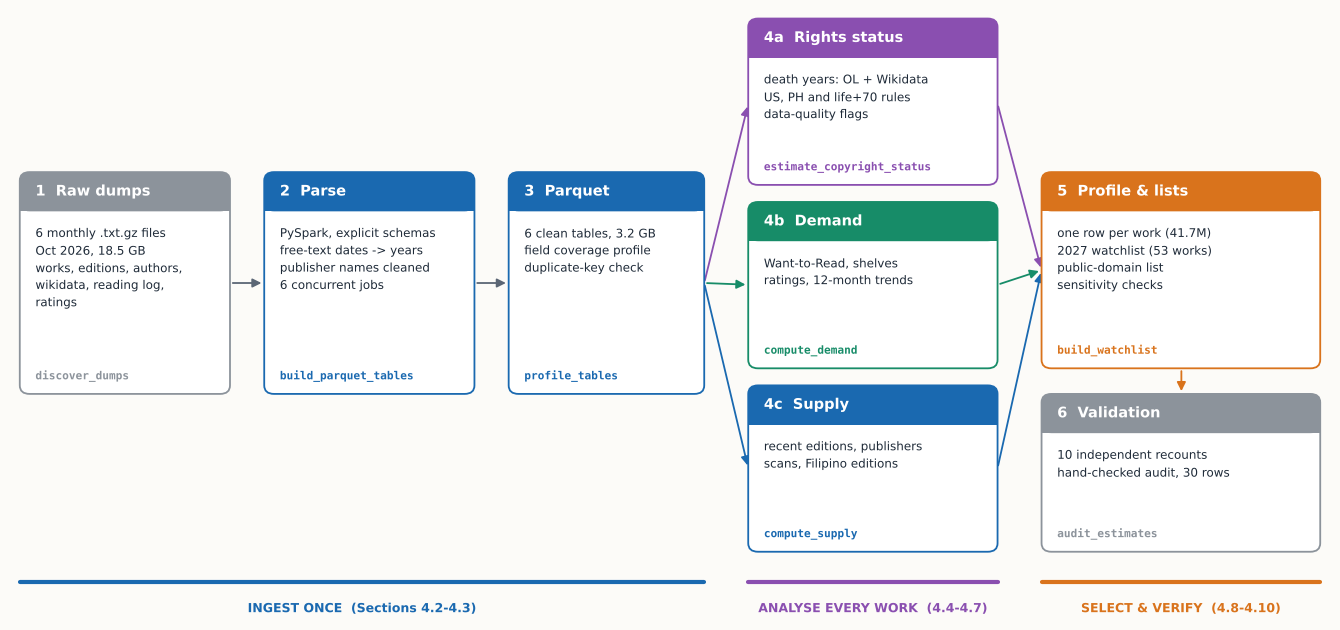

In [1]:
# --- Setup: imports and a small display helper ------------------------
from pathlib import Path
import importlib
import sys
import time

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# All analysis code lives in helper_code.py, which must sit in the same
# folder as this notebook. Jupyter usually starts in that folder, but some
# editors (VS Code, JupyterHub) start elsewhere, so we also look one level
# up and in the repository folder before giving up with a clear message.
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "bdcc-lab-2-"]
HELPER_DIR = next((folder for folder in candidates
                   if (folder / "helper_code.py").is_file()), None)
if HELPER_DIR is None:
    raise FileNotFoundError(
        "helper_code.py not found. Put it in the same folder as this "
        f"notebook (Jupyter is currently running in {Path.cwd()}), or "
        "os.chdir() to that folder, then restart the kernel and Run All."
    )
sys.path.insert(0, str(HELPER_DIR.resolve()))
import helper_code as helper

# Reloading means edits to helper_code.py take effect without a restart.
helper = importlib.reload(helper)

# This notebook needs the updated helper (with the report style and the
# pipeline diagram); an older copy of helper_code.py lacks them.
missing = [name for name in ("use_report_style", "notebook_css",
                             "plot_pipeline_diagram", "audit_estimates",
                             "selection_funnel")
           if not hasattr(helper, name)]
if missing:
    raise ImportError(
        f"{HELPER_DIR / 'helper_code.py'} is an older version without "
        f"{missing}. Replace it with the latest helper_code.py from the "
        "revise-prose-sections-1-2-4 branch."
    )


# One colour system for charts, the diagram, headings and tables (see the
# INK / AMBER / GREEN / PLUM constants in helper_code.py).
helper.use_report_style()
display(HTML(helper.notebook_css()))


def show(table, title=None, rows=10, index=False, floats=2, formats=None):
    # Display a caption, then the first `rows` rows of a pandas table as
    # styled HTML. Whole numbers get thousands separators, other numbers
    # `floats` decimals (or a per-column format from `formats`), text is
    # left-aligned, and a caption starting "Table N." has its label coloured.
    if title:
        label, _, rest = title.partition(". ")
        caption = (f"<span>{label}.</span> {rest}"
                   if label.startswith("Table ") and rest else title)
        display(HTML(f'<div class="report-caption">{caption}</div>'))
    if table is None or len(table) == 0:
        print("No rows meet the stated selection criteria.")
        return
    view = table.head(rows)
    if index:
        view = view.reset_index()
    column_formats = {}
    for column in view.columns:
        name = str(column).lower()
        if "year" in name or "death" in name:
            column_formats[column] = "{}"      # years: no separator
        elif pd.api.types.is_integer_dtype(view[column]):
            column_formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(view[column]):
            column_formats[column] = f"{{:,.{floats}f}}"
    column_formats.update(formats or {})
    text_columns = [col for col in view.columns
                    if not pd.api.types.is_numeric_dtype(view[col])]
    html = (view.style.format(column_formats, na_rep="-")
            .set_properties(subset=text_columns, **{"text-align": "left"})
            .hide(axis="index").to_html())
    display(HTML('<div class="report-table" '
                 'style="overflow-x:auto;max-width:1100px">'
                 + html + "</div>"))


# Figure 1: the pipeline diagram (drawn from code, so no data is needed).
fig = helper.plot_pipeline_diagram()
plt.show()

**Figure 1.** The analysis pipeline, from the six raw Open Library dumps to the validated 2027 watchlist and public-domain list. Coloured lanes group the stages into three phases: ingesting the dumps once into Parquet (blue), analysing rights status, demand and supply for every work (purple), and selecting and verifying the lists (amber). Each card names the helper function that implements its stage, and card colours follow the report's colour system, in which blue marks data processing, purple rights and uncertainty, green demand, amber the 2027 opportunity and grey inputs and checks.

### 4.2 Setup and ingestion with PySpark

Open Library publishes each dump as a single gzip-compressed text file, although the files differ in layout. Three of them (works, editions and authors) share five tab-separated columns, namely record type, key, revision, last-modified time and the record itself as JSON, whereas the Wikidata file wraps each item's JSON in CSV-style quotes and the reading-log and ratings files are plain tab-separated tables.

For each dump, `build_parquet_tables` reads the lines as text, splits the columns and parses only the JSON fields we need against an **explicit schema** (`works_schema`, `editions_schema` and so on), using Spark's built-in JSON functions (Apache Software Foundation, 2025). Declaring the schema pays off in three ways: Spark does not have to scan the file to guess types, the output keeps the same columns every month, and fields we never use, such as table-of-contents text, are skipped rather than loaded into memory. The cleaned tables are then saved as **Parquet**, a compressed column format that later steps can read in parallel within seconds.

Two practical details shape this step. Because a gzip file cannot be split, Spark, which normally gains its speed by dividing a file into many parallel tasks (Zaharia et al., 2016), must read each dump with a single task, so we submit the six dumps as concurrent jobs that let the cores work on different files at the same time. Each table is also written only once and then reused, meaning a later run skips the parsing whenever a table's Parquet folder is already complete. As a result, only the first run is slow, taking about an hour on a 4-core machine because of the 12.6 GB editions file, whereas later runs finish in minutes.

A complete Parquet folder also makes its raw dump unnecessary, which mattered in our run because Spark needs free disk space for the temporary "shuffle" files it writes during large joins. During development we therefore deleted the two largest raw files (works and editions) after checking that the editions table held exactly as many records as the raw file had lines (56,900,885), so a run on that machine lists those two files as not present in Table 2, whereas a run on Jojie, where the shared dumps are kept, lists all six. Table 3 gives the number of rows in each resulting Parquet table.

**Running the notebook.** On Jojie, the course's JupyterHub server, the dumps sit in the shared data folder, which `resolve_data_dir` finds automatically by searching `/mnt/data/public`; on any other machine, place the `ol_dump_*.txt.gz` files in a `data/` folder beside the notebook or point the `OL_DATA_DIR` environment variable at their location. The first run writes the Parquet tables to a `parquet/` folder beside the notebook, which needs about 7 GB including the intermediate tables, and two further environment variables adapt Spark to a shared server: `OL_SPARK_MEMORY` lowers its memory from the default 10 GB, and `OL_SPARK_LOCAL_DIR` moves its temporary files off a small `/tmp`. Because the narrative quotes the 31 October 2026 dumps, the cell below also checks the dumps' dates and warns if they differ. The dumps themselves are listed at <https://openlibrary.org/developers/dumps> (Open Library, 2026), with mirrors on the Internet Archive under the name `ol_dump_YYYY-MM-DD`.

In [2]:
# --- Start Spark and locate the data ------------------------------------
# One local Spark session uses every core on this machine (local[*]).
spark = helper.create_spark()

# Where the raw dumps and the Parquet tables live. On Jojie the dumps are
# found under /mnt/data/public automatically; elsewhere use ./data, or set
# OL_DATA_DIR / OL_PARQUET_DIR to override either location.
DATA_DIR = helper.resolve_data_dir()        # $OL_DATA_DIR, Jojie, ./data
PARQUET_DIR = helper.resolve_parquet_dir()  # ./parquet or $OL_PARQUET_DIR

# A raw dump may be absent once its Parquet table exists (see Section 4.2),
# so missing dumps are allowed here; ingestion stops only if a table has
# neither a Parquet folder nor a raw file.
dumps = helper.discover_dumps(DATA_DIR, required=False)
show(helper.dump_inventory(dumps, PARQUET_DIR),
     "Table 2. Open Library dumps dated 31 October 2026: compressed size of "
     "each raw file (absent once its Parquet table was built) and size of "
     "the resulting Parquet table")
print(f"Spark {spark.version}, {spark.sparkContext.defaultParallelism} "
      "cores, rights evaluated as of", helper.REFERENCE_DATE)

# The narrative quotes the 31 October 2026 dumps; warn if these differ.
print(helper.check_dump_date(dumps))

dump,file,dump_date,raw_gb,parquet_gb,parquet_ready
works,(not present),-,-,1.27,True
editions,(not present),-,-,1.58,True
authors,ol_dump_authors_2026-10-31.txt.gz,2026-10-31,0.78,0.27,True
wikidata,ol_dump_wikidata_2026-10-31.txt.gz,2026-10-31,0.83,0.00,True
reading-log,ol_dump_reading-log_2026-10-31.txt.gz,2026-10-31,0.12,0.11,True
ratings,ol_dump_ratings_2026-10-31.txt.gz,2026-10-31,0.01,0.01,True


Spark 4.0.1, 4 cores, rights evaluated as of 2027-01-01
All dumps are dated 2026-10-31, as described in the text.


In [3]:
# --- Ingestion: dumps -> Parquet ------------------------------------------
# Parse each dump once into Parquet (six concurrent Spark jobs); a table
# whose Parquet folder is already complete is reused, not parsed again.
start = time.time()
parquet_paths = helper.build_parquet_tables(spark, dumps, PARQUET_DIR)

# Open every Parquet table as a Spark DataFrame and count its rows.
tables = helper.load_tables(spark, parquet_paths)
row_counts = pd.DataFrame({
    "table": list(tables),
    "rows": [tables[name].count() for name in tables],
})
show(row_counts, "Table 3. Rows in each cleaned Parquet table after "
     "parsing; one row is one record of the named dump")
print(f"Ingestion step finished in {time.time() - start:,.0f} s")

table,rows
works,"41,731,960"
editions,"56,900,885"
authors,"15,474,645"
wikidata,"169,128"
reading_log,"13,218,055"
ratings,"1,069,316"


Ingestion step finished in 15 s


The screenshots below come from the Spark web UI on port 4040, which lists every job Spark runs together with how many parallel tasks it used.

![Spark UI during ingestion](images/spark_ui_ingestion_jobs.png)

**Figure 2.** Spark jobs page during the one-time ingestion run. Each of the six parsing jobs runs as a single task (`1/1`) because gzip files cannot be split; five jobs have finished, while the job for the 12.6 GB editions dump is still running after 31 minutes (the whole ingestion took 33 minutes).

![Spark UI during the analysis](images/spark_ui_analysis_jobs.png)

**Figure 3.** Spark jobs page during the analysis run of this notebook. Because the Parquet tables can be split, the analysis jobs read them in parallel with up to 64 tasks per stage, and most finish within seconds.

### 4.3 Data quality

Before using a field we measure how often it is present and usable, because a missing value can change a rights estimate: a work without any dated edition, for example, has no first-publication year, so its US status must be "unknown" rather than "protected". To do this, `profile_tables` makes one pass per table, counting the rows whose JSON parsed, the rows that contain each field and the rows whose free-text dates yield a valid year (Table 5).

Years are extracted with a simple, documented rule that takes the first four-digit number between 1450 and 2026 in the text, so "February 27, 1997" gives 1997, "c1931" gives 1931 and "19--" gives no year. Author birth and death dates follow a slightly different rule, keeping the **latest** year in the text ("1850 or 1851" gives 1851), since a later death means longer protection and the estimate should err towards "still in copyright". Finally, `find_duplicate_keys` checks that every work, edition and author key appears only once, as a duplicate would be double-counted in every later join; none does (Table 6).

**Rows kept at parsing.** Parsing drops almost nothing, as Table 4 shows: every record of the editions, authors, Wikidata and ratings dumps was kept, and the only rows removed were 3,031 reading-log entries (0.02%) on a "Stopped Reading" shelf, which lies outside the three standard shelves this analysis uses. Three later joins also exclude records that cannot be attributed to a work, namely 1,882,101 editions (3.3%) with no work link, 4,518 editions that point to works missing from the works dump, and 131,990 Want-to-Read entries (1.2%) on such missing works, which Open Library has usually merged or deleted.

**Table 4.** Records in each raw dump and records kept after parsing, with the reason for every dropped record.

| Dump | Raw records | Kept | Dropped | Reason |
|---|---:|---:|---:|---|
| works | not recounted | 41,731,960 | none found | raw file deleted after parsing; every parsed record was a valid work record |
| editions | 56,900,885 | 56,900,885 | 0 | none |
| authors | 15,474,645 | 15,474,645 | 0 | none |
| wikidata | 169,128 | 169,128 | 0 | none |
| reading-log | 13,221,086 | 13,218,055 | 3,031 (0.02%) | "Stopped Reading" shelf, outside the three standard shelves |
| ratings | 1,069,316 | 1,069,316 | 0 | none; every rating lies between 1 and 5 |

In [4]:
# --- Data quality --------------------------------------------------------
# Share of rows where each field the analysis needs is present and usable
# (one Spark pass per table), then a check that no key is duplicated.
quality = helper.profile_tables(tables)
duplicates = helper.find_duplicate_keys(tables)
show(quality, "Table 5. Coverage of the fields the analysis relies on: "
     "rows with the field present and usable, as a share of all rows",
     rows=40)
show(duplicates, "Table 6. Work, edition and author keys that appear more "
     "than once (a duplicate would be double-counted in every join)")

table,field,rows,non_null,coverage_pct
works,json parsed,"41,731,960","41,731,960",100.00
works,title,"41,731,960","41,731,803",100.00
works,at least one author key,"41,731,960","39,429,636",94.48
works,first_publish_date text,"41,731,960","4,421,545",10.60
works,first_publish_date valid year,"41,731,960","4,420,875",10.59
editions,json parsed,"56,900,885","56,900,885",100.00
editions,linked to a work,"56,900,885","55,018,784",96.69
editions,publish_date text,"56,900,885","55,170,130",96.96
editions,publish_date valid year,"56,900,885","55,046,819",96.74
editions,publisher,"56,900,885","53,660,150",94.30


table,duplicated_keys
works,0
editions,0
authors,0


**Why values are missing and how we handle them.** We never fill in a missing date or death year, because an invented value could turn an unknown into a false claim that a book is free. Table 7 instead records, for each field the analysis relies on, how much is missing, the evidence for why, and what the pipeline does about it. The coverage figures come from Table 5 above, and the evidence comes from the same tables: for instance, 86% of Wikidata-linked authors have a death year but only 3.6% of all Open Library authors do, which shows that death years are missing mainly because most author records were never linked to an authority source, not because most authors are alive.

**Table 7.** Missing values in the fields the analysis relies on, with the likely cause, the evidence for it, and how each is handled.

| Field | Missing | Why it is missing (evidence) | Handling | Justification |
|---|---:|---|---|---|
| work `first_publish_date` | 89.4% of works | optional field; work records are mostly created automatically when editions are imported (35.8M of the dated works get their year from an edition) | use the earliest dated edition instead | editions carry a valid year 96.7% of the time, raising dated works to 96.3% |
| edition year | 3.3% of editions | absent or vague dates in source records ("19--", "n.d.") | edition counted, but never as recent | its age is unknown, so recent-edition counts become lower bounds and "low supply" needs confirming |
| edition → work link | 3.3% of editions | editions imported without being matched to a work | excluded from per-work supply | cannot be attributed to any work |
| edition language | 13.1% of editions | not recorded in many imported records | not counted as Filipino | Filipino-edition counts are therefore lower bounds |
| work → author link | 5.5% of works | anonymous, corporate or incompletely imported works | Philippine status "unknown (no author)" | a life-based term needs a person |
| author death year | 96.3% of authors | most author records lack any authority link; 86% of Wikidata-linked authors do have one | never imputed; status "unknown" | guessing would create false public-domain claims |
| shelf entries and ratings | 93% of works have no entry | most catalogued books have never been shelved | counts set to 0; mean rating left blank | no entry means zero recorded demand, whereas a mean of no ratings is undefined |

### 4.4 Author death years: Open Library and Wikidata

Life-based copyright terms need the death year of **every** author of a work, yet Open Library's own `death_date` field is free text and often empty, so we add structured dates from Wikidata (property P570, date of death; Wikidata contributors, 2026). Without this step only 3.6% of Open Library authors would have a usable death year, too few for the life-based rule to classify more than a sliver of the catalogue. Authors are linked to Wikidata items in either direction, through the author record's `remote_ids.wikidata` value or through a Wikidata item whose property P648 lists the author's Open Library ID. Values that Wikidata marks as *deprecated* (known to be wrong) are ignored, as are dates less precise than a year such as "1900s", and when several items or values remain, the latest death year is used.

When both sources give a year, Wikidata is preferred because its dates are typed and usually referenced. Table 8 shows which source supplies each author's death year, and Table 9 measures how often the two sources match, with its last row counting the authors whose Philippine status would flip depending on which source we trusted, a direct measure of how much this choice matters for the results. Wikidata's country of citizenship (P27 = Q928, Philippines) is kept as well, giving us a way to identify Filipino authors.

In [5]:
# --- Author death years --------------------------------------------------
# Attach one death year to every author: Wikidata (P570) when available,
# otherwise the year parsed from Open Library's free-text death_date.
deaths = helper.reconcile_author_deaths(tables["authors"],
                                        tables["wikidata"])

# Save the result once as Parquet so later cells do not redo the joins.
author_deaths = helper.materialize(
    spark, deaths["author_deaths"], PARQUET_DIR / "author_deaths")
show(deaths["source_summary"],
     "Table 8. Source of each Open Library author's death year: Wikidata, "
     "Open Library's own death_date field, or none")
show(deaths["agreement"].T.reset_index().rename(
    columns={"index": "measure", 0: "value"}),
    "Table 9. Agreement between Open Library and Wikidata death years "
    "for authors with both, including how many authors would change "
    "Philippine status depending on the source", rows=20)

death_source,count,share_pct
none,"14,905,432",96.32
open_library,"408,955",2.64
wikidata,"160,258",1.04


measure,value
authors_with_both,"153,577.00"
exact_match,"149,980.00"
within_one_year,"151,796.00"
differ_over_10,513.00
ph_status_would_flip,75.00
exact_match_pct,97.66
within_one_year_pct,98.84
differ_over_10_pct,0.33
ph_status_would_flip_pct,0.05


### 4.5 Estimating copyright status

We estimate each work's status as it will stand **on 1 January 2027** under two legal regimes, following the rules summarized in Table 10 and implemented in `us_status` and `life_plus_status`.

**Table 10.** Copyright rules used to classify each work on 1 January 2027, where *Y* is the year of first publication and *D* the death year of the last surviving author.

| Regime | Basis | Public domain on 1 Jan 2027 | Enters on 1 Jan 2027 | Uncertain or protected |
|---|---|---|---|---|
| United States (17 U.S.C. sec. 302-304) | first publication year *Y*; 95-year term for works published before 1978 | *Y* ≤ 1930 | *Y* = 1931 | 1932-1963: PD only if the copyright was not renewed (renewal records are not in Open Library); 1964 onwards: protected |
| Philippines (RA 8293, sec. 213-214) | death year *D* of the last surviving author; life + 50 years | *D* ≤ 1975 | *D* = 1976 | *D* ≥ 1977 protected; any author without a death year: unknown |
| Life + 70 (EU, UK and others), for comparison | as above, life + 70 | *D* ≤ 1955 | *D* = 1956 | *D* ≥ 1957 protected |

The boundary years in the table follow from two short formulas. A US work published in year $Y$ before 1978 is protected for 95 years, with the term running to the end of the calendar year (Copyright Act of 1976; Hirtle, 2026), so it becomes free on

$$\text{US free date} = \text{1 January of } (Y + 96) \tag{1}$$

In the Philippines, protection lasts 50 years counted from 1 January of the year after the last surviving author's death $D$ (Intellectual Property Code of the Philippines, 1997), which gives

$$\text{PH free date} = \text{1 January of } (D + 51) \tag{2}$$

and the life + 70 comparison rule simply replaces 51 with 71. Setting either free date in Equations (1) and (2) equal to 2027 recovers the "enters" column of Table 10, since $1931 + 96 = 2027$, $1976 + 51 = 2027$ and $1956 + 71 = 2027$.

A work's **first-publication year** is the earlier of the work record's `first_publish_date` and its earliest dated edition, which matches how Open Library itself reports "first published". Even so, a single misdated edition can make a work look older than it is, so two checks guard against this:

* `year_before_birth` marks works whose first year falls before the last author's birth year plus 10, which is implausible for a genuine first edition, so these works stay in the counts but are **flagged** and excluded from every list. The 10-year margin is deliberately loose, catching only first years that are impossible for the author rather than merely unusual ones.
* `gap_after_death` marks works whose first year comes more than 70 years after the last author's death, suggesting that the catalogue lacks the older editions or that the work is linked to the wrong, much older author. We chose 70 years because it is the longest common copyright term (life + 70), so a genuine book would have to make its debut after every common term had already run out, which is rare.

A work is called **potentially public domain** if it is unflagged and public domain under either the US or the Philippine rule, while it **enters in 2027** if it is unflagged and enters under either rule. Table 11 below counts the works caught by each flag, and Table 12 compares the three regimes side by side, which is the only place the life + 70 rule is reported.

In [6]:
# --- Copyright status -----------------------------------------------------
# For every work: first-publication year, the authors' last death year,
# data-quality flags and a status code under the US, PH and life+70 rules.
status = helper.materialize(
    spark,
    helper.estimate_copyright_status(tables["works"], tables["editions"],
                                     author_deaths),
    PARQUET_DIR / "work_status",
)
status_summary = helper.summarize_status(status)
show(status_summary["flags"],
     "Table 11. Works in the catalogue, works caught by each data-quality "
     "flag, and the two headline groups (unflagged works only)")

# Side-by-side counts under all three regimes, including life + 70.
show(helper.status_by_regime(status).reset_index(),
     "Table 12. Works per status group on 1 January 2027 under the US "
     "rule, the Philippine rule and the life + 70 comparison rule",
     floats=0)

works,year_before_birth,author_dates_conflict,gap_after_death,potentially_pd,enters_2027
"41,731,960",72390,"4,697",950690,"6,058,714","96,544"


Status on 1 Jan 2027,United States (publication + 95),Philippines (life + 50),Life + 70 (comparison)
Public domain already,"4,610,752","3,416,755","2,941,511"
Enters 1 Jan 2027,"71,810","25,129","23,830"
Renewal unknown (US only),"3,006,722",0,0
Protected,"32,508,233","903,403","1,379,946"
Unknown (missing data),"1,534,443","37,386,673","37,386,673"


### 4.6 Demand: reading log and ratings

Open Library readers can place a work on one of three shelves (*Want to Read*, *Currently Reading* or *Already Read*) and rate it from one to five stars, and the dumps record one row for each such entry or rating, together with its date but without any user identifier. Since readers cannot be told apart, `compute_demand` counts entries per work (catalogue-wide totals in Tables 13 and 14), treating Want-to-Read entries as the main **demand** signal because they record books people intend to read but may not yet have.

To describe **trends**, we count the Want-to-Read entries made in the 12 months to 31 October 2026 and in the 12 months before that, and we also chart monthly entries for each rights group. One caution applies throughout, because the dump holds only entries that are *still* on a shelf: once a reader finishes or removes a book, its older Want-to-Read entry disappears. Older months are consequently undercounted, so part of any upward slope reflects this survivorship rather than growing interest.

In [7]:
# --- Demand ---------------------------------------------------------------
# Per-work shelf counts, 12-month Want-to-Read windows and ratings (lazy:
# Spark computes them only when the work profile is built in Section 4.7).
demand = helper.compute_demand(tables["reading_log"], tables["ratings"])

# Catalogue-wide totals by shelf and by star value.
shelf_summary = helper.summarize_shelves(tables["reading_log"],
                                         tables["ratings"])
show(shelf_summary["shelves"],
     "Table 13. Reading-log entries and distinct works on each of the "
     "three standard shelves")
show(shelf_summary["ratings"],
     "Table 14. Number of ratings at each star value (1 to 5)")

shelf,entries,distinct_works
Want to Read,"10,880,749","2,943,435"
Already Read,"1,706,894","881,990"
Currently Reading,"630,412","323,367"


rating,count
1,"34,376"
2,"35,656"
3,"110,890"
4,"597,500"
5,"290,894"


### 4.7 Supply: editions, publishers, scans and Filipino editions

For each work, `compute_supply` summarizes its editions in four ways:

* **Editions** and **recent editions**, the latter meaning those published in 2017-2026, the ten years up to the dump. Ten years is long enough to catch any edition a publisher is still actively selling and short enough to leave out reprints that went out of print long ago, so a wanted work with no recent edition is an opening, whereas one that many publishers keep reissuing is already well served.
* **Publishers** and **recent publishers**, counted after names are normalized (lower case, punctuation removed, legal suffixes such as "Ltd." dropped) so that "Penguin Books Ltd." and "Penguin Books" count once.
* **Digitized copies**, meaning editions with an Internet Archive scan (`ocaid`), which show that a scanned source text exists, although scans of books still in copyright are only lent to one reader at a time rather than offered freely.
* **Filipino-language editions**, catalogued with the language codes `tgl` (Tagalog) or `fil` (Filipino), which mark the gap a Philippine translation could fill.

Editions without a valid year count as editions but never as recent ones, making the recent counts lower bounds. Rights status, demand and supply are then joined into one **work profile** row per work, in which works nobody has shelved receive zero counts rather than missing values.

In [8]:
# --- Supply and the work profile ----------------------------------------
# Per-work edition counts (all, recent, scanned, Filipino) and publishers.
supply = helper.compute_supply(tables["editions"])

# Join status, demand and supply into one row per work (zeros, not blanks,
# for works with no shelf entries or editions) and save it as Parquet.
profile = helper.materialize(
    spark, helper.build_work_profile(status, demand, supply),
    PARQUET_DIR / "work_profile",
)
print(f"Work profile: {profile.count():,} works x "
      f"{len(profile.columns)} columns")

Work profile: 41,731,960 works x 38 columns


### 4.8 Watchlist and public-domain list

The **2027 watchlist** keeps only the works that meet all three of these conditions:

1. they **enter the public domain on 1 January 2027** under the US rule
   (first published 1931) or the Philippine rule (last author died 1976),
   with no data-quality flag;
2. they are in **high demand**: their Want-to-Read count is at least the
   99th percentile among all works with at least one entry (most works in
   the catalogue have none, so a percentile over all works would be zero);
3. they have **low recent supply**: at most one edition since 2017.

Both cut-offs follow from the shape of the data. Demand on Open Library is extremely skewed, since the median shelved work has a single Want-to-Read entry, 62% of shelved works have exactly one, and the top 1% (29,632 works with 33 or more entries) hold 37% of all entries. A threshold at the 99th percentile therefore separates sustained interest from one-off shelving, and it also keeps the watchlist short enough (53 works) to be checked by hand, which Section 4.10 shows is necessary. Allowing one recent edition rather than none tolerates a single print-on-demand reprint, or a recent edition attached to the wrong work record, while still excluding works that publishers are actively reissuing.

Works on the list are ranked by Want-to-Read entries, then by entries in the last 12 months, then by number of ratings. The **potentially public domain list** applies the same demand threshold to works that are already free under either rule, and Table 15 shows how many works survive each filtering step of both lists, together with the share kept at every step.

Because both cut-offs remain judgement calls, alternative assumptions are tested rather than assumed. Section 5.4 varies the demand quantile (90th, 95th, 99th) and the supply limit (0 to 5 recent editions), Table 12 reports the stricter life + 70 rule alongside the two main regimes, and Table 9 shows how many authors would change Philippine status if Open Library's death dates were trusted over Wikidata's.

In [9]:
# --- Watchlist and public-domain list -----------------------------------
WTR_QUANTILE = 0.99          # "high demand" = top 1% of shelved works
MAX_RECENT_EDITIONS = 1      # "low supply" = at most one edition since 2017

# Want-to-Read count at the 99th percentile of works with any entry (33).
min_wtr = helper.demand_threshold(profile, WTR_QUANTILE)

# The full watchlist (a Spark DataFrame) is kept for the validation step;
# the top 50 rows of each list are brought into pandas with author names.
watchlist_all = helper.build_watchlist(profile, min_wtr,
                                       MAX_RECENT_EDITIONS)
watchlist = helper.build_watchlist(profile, min_wtr, MAX_RECENT_EDITIONS,
                                   top_n=50, authors=tables["authors"])
pd_list = helper.build_pd_list(profile, min_want_to_read=min_wtr,
                               top_n=50, authors=tables["authors"])
print(f"High-demand threshold: at least {min_wtr} Want-to-Read entries "
      f"(the {WTR_QUANTILE:.0%} quantile among works with any entry)")
print(f"Works on the 2027 watchlist: {watchlist_all.count():,}")

# Works remaining after each filtering step, for both lists.
funnel = helper.selection_funnel(profile, min_wtr, MAX_RECENT_EDITIONS)
show(funnel.rename(columns={
    "list": "List", "step": "Filtering step", "works": "Works kept",
    "pct_of_previous": "% of previous step",
    "pct_of_catalogue": "% of catalogue"}),
     "Table 15. Works remaining after each filtering step of the 2027 "
     "watchlist and the public-domain list, as a share of the previous "
     "step and of the whole catalogue",
     formats={"% of previous step": "{:.2f}", "% of catalogue": "{:.4f}"})

High-demand threshold: at least 33 Want-to-Read entries (the 99% quantile among works with any entry)


Works on the 2027 watchlist: 53


List,Filtering step,Works kept,% of previous step,% of catalogue
2027 watchlist,all works in the catalogue,"41,731,960",100.00,100.0000
2027 watchlist,no data-quality flag,"41,655,385",99.82,99.8165
2027 watchlist,enters the public domain on 1 Jan 2027,"96,544",0.23,0.2313
2027 watchlist,high demand (>= 33 Want-to-Read),146,0.15,0.0003
2027 watchlist,low supply (<= 1 recent edition),53,36.30,0.0001
public-domain list,all works in the catalogue,"41,731,960",100.00,100.0000
public-domain list,no data-quality flag,"41,655,385",99.82,99.8165
public-domain list,public domain already (US or PH rule),"6,058,714",14.54,14.5182
public-domain list,high demand (>= 33 Want-to-Read),"2,352",0.04,0.0056


### 4.9 Computational validation

Aggregations over tens of millions of rows can fail silently, as when a join drops or duplicates rows, so `validate_analysis` recounts key totals along a different code path and compares the two answers. The number of editions attached to known works, for instance, is counted directly from the editions table and then checked against the sum of the per-work edition counts. The function also re-applies the Python versions of the US and Philippine rules to a random 0.1% sample of works, confirming that Spark assigned exactly the same status to each. All ten checks and their results are listed in Table 16.

In [10]:
# --- Computational validation ------------------------------------------
# Ten checks, each comparing a published total with an independent recount
# (for example raw edition rows vs the sum of per-work edition counts).
validation = helper.validate_analysis(
    tables, status, profile, watchlist_all, min_wtr, MAX_RECENT_EDITIONS)
show(validation, "Table 16. Ten computational checks: each published "
     "total (actual) against an independent recount (expected)", rows=20)
print(f"{int(validation['passed'].sum())} of {len(validation)} checks "
      "passed")

check,expected,actual,passed
profile has one row per work,"41,731,960","41,731,960",True
profile work keys are unique,"41,731,960","41,731,960",True
US status groups sum to all works,"41,731,960","41,731,960",True
edition rows linked to known works = sum of n_editions,"55,014,266","55,014,266",True
Want-to-Read rows on known works = sum of want_to_read,"10,748,759","10,748,759",True
digitized editions on known works = sum of n_digitized,"6,425,294","6,425,294",True
recent editions on known works = sum of n_recent_editions,"11,888,905","11,888,905",True
every watchlist row meets all three criteria,0,0,True
Spark US rule = Python US rule (0.1% sample),"41,910","41,910",True
Spark PH rule = Python PH rule (0.1% sample),"41,910","41,910",True


10 of 10 checks passed


### 4.10 Hand-checked audit of the top-ranked rows

The recounts in Section 4.9 confirm that the code adds up the data correctly, but they cannot reveal whether the data themselves are right, so we also checked the 15 top-ranked rows of each list by hand. For every row we looked up the year of first publication and the death year of the last author in publisher, library and encyclopaedia records, then recomputed the status with the same rule functions the pipeline uses (`audit_estimates`), which means any disagreement must come from the catalogue rather than from the rules. A value we could not confirm from a reliable source was marked "not checked" instead of being guessed.

Table 17 summarizes the outcomes and Table 18 lists every audited row. These rows were chosen because they are the ones a reader would act on first, so they are not a random sample. Famous works also tend to be catalogued more carefully than obscure ones, which means the audit is more likely to flatter the accuracy of the lists' long tail than to understate it.

In [11]:
# --- Hand-checked audit -------------------------------------------------
# helper.AUDIT_SAMPLE holds the hand-checked first year and last-author death
# year for the 15 top rows of each list; audit_estimates re-applies the same
# US and PH rules to those facts and compares the results with the estimates.
audit = helper.audit_estimates(profile)
show(helper.audit_summary(audit),
     "Table 17. Hand-checked audit outcomes by list and regime: number of "
     "rows whose estimated status was correct, wrong, missing in the data "
     "or not checkable", floats=0)
show(audit[["list", "title", "est_year", "checked_year", "est_death",
            "checked_death", "us_outcome", "ph_outcome", "verdict",
            "note"]],
     "Table 18. Hand-checked audit of the 15 top-ranked rows of each list: "
     "estimated and checked first year and death year, outcome per regime "
     "and the source note", rows=30)
print(f"Status correct for {(audit['verdict'] == 'correct').sum()} of "
      f"{len(audit)} audited rows")

list,regime,correct,wrong,missing in data,not checked
2027 watchlist,United States,13,2,0,0
public domain,United States,15,0,0,0
2027 watchlist,Philippines,11,0,1,3
public domain,Philippines,14,0,0,1


list,title,est_year,checked_year,est_death,checked_death,us_outcome,ph_outcome,verdict,note
2027 watchlist,Joy of Cooking,1931,1931,1962,-,correct,not checked,correct,1931 text only; later revisions by co-authors remain protected
2027 watchlist,Interaction of Colour,1963,1963,1976,1976,correct,correct,correct,Yale UP 1963; Albers d. 1976
2027 watchlist,Johnny Got His Gun,1939,1939,1976,1976,correct,correct,correct,Trumbo d. 1976
2027 watchlist,The laws of human nature,1931,1931,1962,-,correct,not checked,correct,London (Nisbet) 1931; demand may be confused with a 2018 title
2027 watchlist,Industrial Accident Prevention,1931,1931,-,1962,correct,missing in data,correct,McGraw-Hill 1st ed. 1931; author death missing in the data
2027 watchlist,Let's go play at the Adams',1974,1974,1976,1976,correct,correct,correct,Crowell 1974; Johnson d. 1976
2027 watchlist,The Secret at Shadow Ranch,1931,1931,1977,2002,correct,correct,correct,"Ghostwritten by M. Wirt Benson (d. 2002), not the linked author"
2027 watchlist,Light in August,1931,1932,1962,1962,wrong,correct,wrong,"Published October 1932, not 1931"
2027 watchlist,What life should mean to you,1931,1931,1937,1937,correct,correct,correct,Adler d. 1937
2027 watchlist,Call It Courage,1940,1940,1976,1976,correct,correct,correct,Sperry d. 1976


Status correct for 28 of 30 audited rows


The estimated status was correct for 28 of the 30 audited rows, and the US rule produced both errors, each caused by a wrong catalogue year. *Light in August* is listed as 1931 but was published in October 1932, so it enters the US public domain in 2028 rather than 2027, whereas *Cours de linguistique générale* is listed as 1931 although it first appeared in 1916, making it already free rather than newly free. The Philippine rule was right wherever it could be checked, yet one of its correct answers rested on a wrong input, since *The Secret at Shadow Ranch* is linked to Leslie McFarlane instead of its actual ghostwriter, Mildred Wirt Benson; both died after 1976, so the status happens to be unaffected. Two lessons follow for how the lists should be used: the catalogue year of any work in the 1931 group must be confirmed against a first-edition record before a decision is made, and an author link can be wrong even when the resulting status looks right.

## 5 Results and Discussion

### 5.1 How much of the catalogue is, or will be, public domain?

Under the **US rule**, 4.61 million works (11.1%) were first published in
1930 or earlier and are already public domain. Another 71,810 (0.2%) date
from 1931 and enter on 1 January 2027. A further 3.01 million (7.2%) are in
the 1932-1963 "renewal unknown" window: many of these are probably free,
because most copyrights from that period were never renewed, but the
dumps cannot tell us which. Most of the catalogue (69.2%) was first
published in 1978 or later.

The **Philippine rule** gives a very different picture, mostly because of
missing data. 84.1% of works have at least one author without a death
year and 5.5% have no linked author, so only 10.4% can be classified at
all. Of those, most are already free (3.42 million works, 8.2% of the
catalogue), 903,403 are protected, and 25,129 enter in 2027.

The cross-tabulation below shows where the two regimes disagree. **1.51
million works are public domain in the Philippines but not clearly so in
the US**, including 764,857 first published after 1977, typically
posthumous editions or translations of authors who died long ago. In the
other direction, 15,215 works published in 1930 or earlier are still
protected in the Philippines because one of their authors died after
1976 (for example a modern translator or editor credited as an author).
This is the gap the game plan anticipated: each country's rule frees a
different set of works, and the life-based rule frees some much earlier.

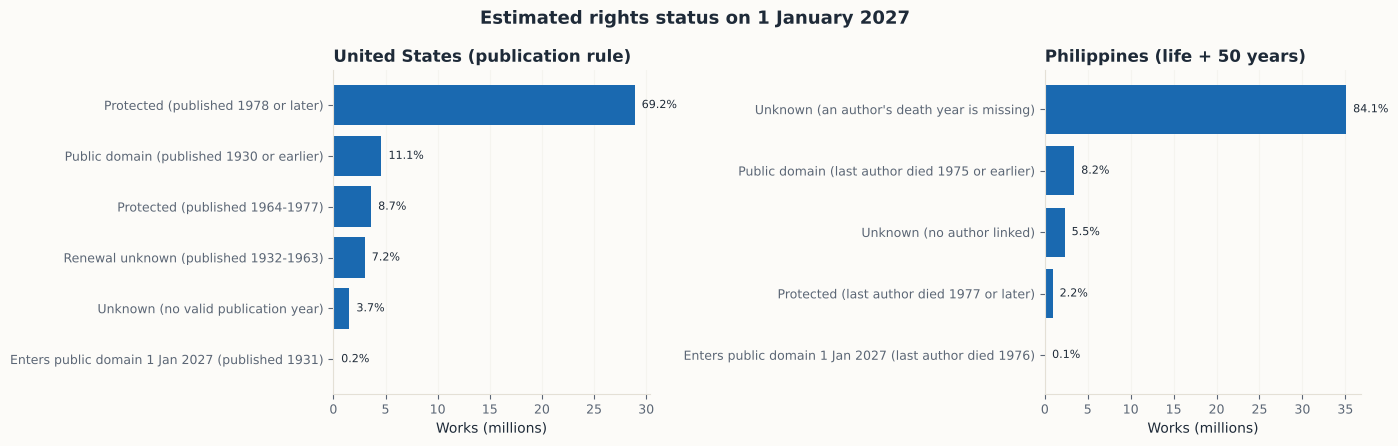

US status,Enters public domain 1 Jan 2027 (last author died 1976),Protected (last author died 1977 or later),Public domain (last author died 1975 or earlier),Unknown (an author's death year is missing),Unknown (no author linked)
Enters public domain 1 Jan 2027 (published 1931),136,"1,591","17,567",51007,"1,509"
Protected (published 1964-1977),"6,485","200,137","214,077",3069682,"128,248"
Protected (published 1978 or later),"7,017","504,279","765,879",26603641,"1,008,788"
Public domain (published 1930 or earlier),"1,629","15,215","1,903,568",2448885,"241,455"
Renewal unknown (published 1932-1963),"9,415","163,495","444,313",2313798,"75,701"
Unknown (no valid publication year),447,"18,686","71,351",597336,"846,623"


In [12]:
fig = helper.plot_status_bars(status_summary["us"], status_summary["ph"])
plt.show()
show(status_summary["crosstab"].reset_index(),
     "Works by US status (rows) and Philippine status (columns)", rows=10,
     floats=0)

The histogram of first-publication years (log scale) shows the steady
growth of publishing, with colours marking the US groups. Two spikes are
**data artefacts** rather than history: 131,598 works are dated exactly
**1900** (about twice the neighbouring years) and 26,149 exactly **1800**,
which look like placeholder dates used by some catalogue sources. Both
are before 1931, so the affected works count as public domain in the US;
if their real dates are later, this group is overstated.

Three data-quality flags quantify the remaining uncertainty:

* **72,390 works** have a first year earlier than their author's birth
  plus 10 years (`year_before_birth`), and **4,697** have authors with
  impossible life dates. These 0.2% are flagged and excluded from every
  list.
* **950,690 works** were first catalogued more than 70 years after their
  last author died (`gap_after_death`). Most are classics whose early
  editions are simply missing (*The Art of War*, *Meditations*). Some,
  however, are modern books linked to the wrong, much older author.
  Section 5.5 measures how often this affects the lists.

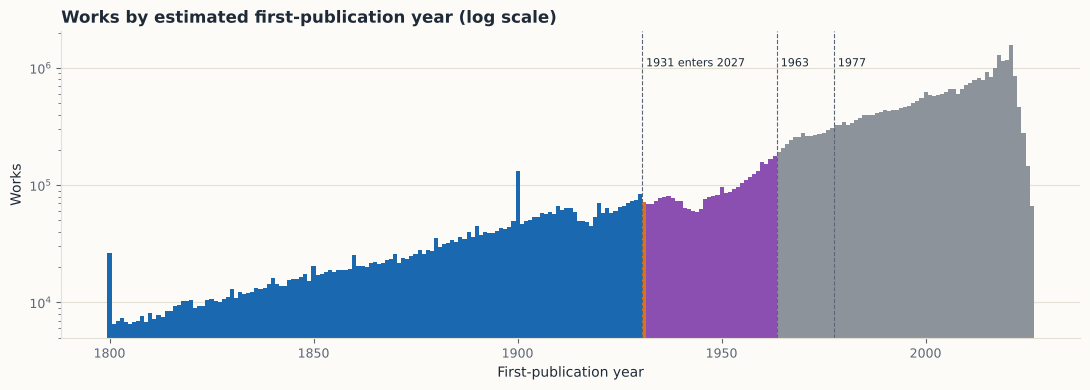

In [13]:
hist = helper.first_year_histogram(status)
fig = helper.plot_first_year_histogram(hist)
plt.show()

### 5.2 Reading activity and Want-to-Read trends

Older works are shelved less often per work than new ones. 3.5% of
public-domain works have at least one Want-to-Read entry, compared with
8.1% of post-1978 works. But because the public-domain group is large,
it still collects **586,358 Want-to-Read entries**, and the 1932-1963 group
another 688,552. Ratings are almost identical across groups (mean 3.9-4.1
stars). A reader who finds an older book is about as satisfied as one
reading a recent title, so age itself does not signal weak demand.

US status,Works,With any WTR (%),Mean WTR per work,Total WTR,WTR Nov 2024-Oct 2025,WTR Nov 2025-Oct 2026,Change (%),Ratings,Mean stars
Public domain (published 1930 or earlier),"4,610,752",3.45,0.13,"586,358","99,449","93,757",-5.70,"39,552",4.07
Enters public domain 1 Jan 2027 (published 1931),"71,810",3.95,0.11,"8,176","1,324","1,137",-14.10,409,3.89
Renewal unknown (published 1932-1963),"3,006,722",4.90,0.23,"688,552","116,918","97,820",-16.30,"50,327",4.04
Protected (published 1964-1977),"3,618,629",5.89,0.21,"748,284","118,546","99,222",-16.30,"91,379",4.00
Protected (published 1978 or later),"28,889,604",8.11,0.30,"8,621,461","1,594,682","1,089,496",-31.70,"870,442",4.00
Unknown (no valid publication year),"1,534,443",3.15,0.06,"95,928","18,794","9,823",-47.70,"5,236",3.92


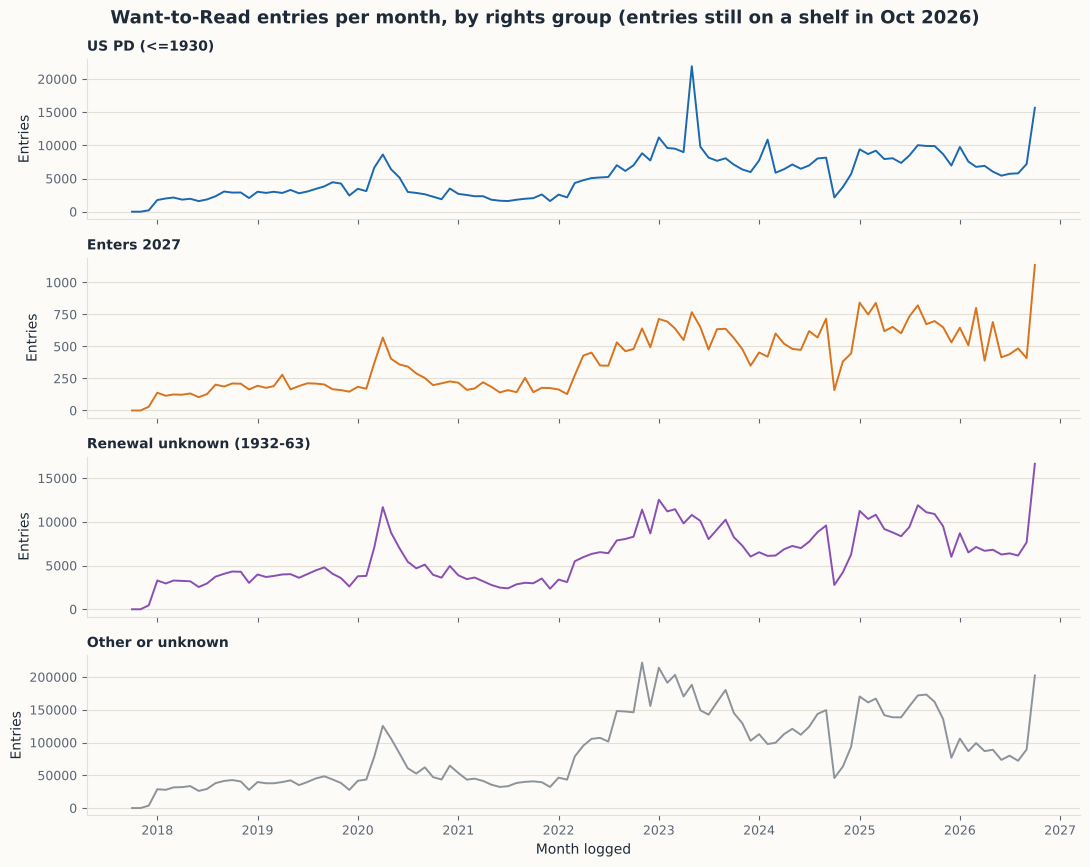

In [14]:
groups = helper.compare_groups(profile)
show(groups[["US status", "works", "pct_with_wtr", "mean_wtr",
             "total_wtr", "wtr_prev_12m", "wtr_last_12m", "wtr_growth_pct",
             "ratings", "mean_rating"]].rename(columns={
    "works": "Works", "pct_with_wtr": "With any WTR (%)",
    "mean_wtr": "Mean WTR per work", "total_wtr": "Total WTR",
    "wtr_prev_12m": "WTR Nov 2024-Oct 2025",
    "wtr_last_12m": "WTR Nov 2025-Oct 2026",
    "wtr_growth_pct": "Change (%)", "ratings": "Ratings",
    "mean_rating": "Mean stars"}),
    "Demand by US rights group", floats=2)
monthly = helper.monthly_want_to_read(tables["reading_log"], status)
fig = helper.plot_monthly_wtr(monthly)
plt.show()

The monthly chart shows four features that matter for interpreting
trends:

1. **Activity grows from 2022.** Monthly entries rise severalfold in
   every group between 2021 and 2023, in step with Open Library's overall
   growth, so raw growth mostly reflects more users rather than more
   interest in particular books.
2. **A sharp dip in October 2024** appears in all four groups at once.
   It coincides with the period when the Internet Archive, which runs Open
   Library, was offline after a cyber-attack, so it reflects service
   availability, not reader interest.
3. **The last month is the highest.** Entries made recently have had the
   least time to be removed from shelves, so recent months are inflated
   relative to older ones (the survivorship effect described in Section 4.6).
4. **Group spikes.** The public-domain line has an isolated spike in
   May 2023 that does not appear elsewhere. A single popular list or
   import is the likeliest cause, so we do not read it as a trend.

Comparing the last 12 months with the 12 before, entries fell in every
group, but by very different amounts: **−5.7% for US public-domain
works against −31.7% for post-1978 works**. As a result, public-domain works
rose from 5.1% to 6.7% of all Want-to-Read activity. Both windows are
equally affected by the outage dip (it falls in the earlier window) and
by survivorship (which favours the later window), so the *relative*
change between groups is more trustworthy than the absolute decline.

### 5.3 Supply: editions, publishers, scans and Filipino editions

The supply indicators show the expected pattern, plus one notable gap:

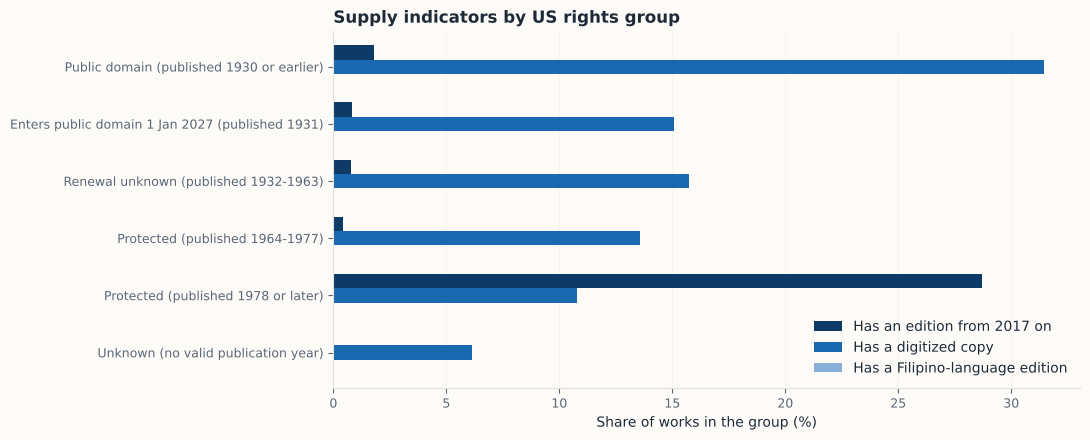

US status,Mean editions,Edition since 2017 (%),Digitized (%),Filipino edition (%)
Public domain (published 1930 or earlier),1.55,1.80,31.47,0.01
Enters public domain 1 Jan 2027 (published 1931),1.35,0.83,15.07,0.00
Renewal unknown (published 1932-1963),1.38,0.80,15.73,0.01
Protected (published 1964-1977),1.28,0.42,13.58,0.01
Protected (published 1978 or later),1.30,28.71,10.78,0.01
Unknown (no valid publication year),0.93,0.00,6.12,0.00


Want to Read,0,1-2,3-9,10+
0,"5,587,423","246,848","37,874","2,932"
1-9,"231,379","11,862","6,260","2,616"
10-99,"5,694",812,617,"1,079"
100-999,200,68,105,352
1000+,3,1,3,62


In [15]:
fig = helper.plot_supply_comparison(groups)
plt.show()
show(groups[["US status", "mean_editions", "pct_with_recent_edition",
             "pct_digitized", "pct_filipino"]].rename(columns={
    "mean_editions": "Mean editions",
    "pct_with_recent_edition": "Edition since 2017 (%)",
    "pct_digitized": "Digitized (%)",
    "pct_filipino": "Filipino edition (%)"}),
    "Supply by US rights group", floats=2)
grid = helper.demand_supply_grid(profile)
show(grid.reset_index(),
     "Public-domain and 2027 works: Want-to-Read band x recent editions",
     floats=0)

* **Recent editions are rare for older works.** Only 1.8% of US
  public-domain works, 0.8% of 1931 works and 0.8% of 1932-1963 works have
  an edition dated 2017 or later, compared with 28.7% of post-1978 works.
  Most old works are effectively out of print in the catalogue.
* **Scans are common for older works.** 31.5% of public-domain works have
  an Internet Archive scan, roughly three times the rate for post-1978
  works. A scan does not mean the book is free to read online, though:
  in-copyright scans are only lent, one reader at a time.
* **Filipino-language editions are almost absent.** Across the whole
  catalogue only 4,252 works (4,619 editions) are catalogued in Tagalog
  or Filipino, about 0.01% in every group. Part of this is under-cataloguing
  of Philippine publishers in Open Library, but the gap is large enough to
  suggest a real shortage of Filipino editions of world literature.

The demand-supply grid restricts attention to works that are potentially
public domain or enter in 2027. Of the 794 such works with 100 or more
Want-to-Read entries, **203 have no edition since 2017** (3 of them with
over 1,000 entries). These are the clearest "wanted but not reissued"
cases. The grid also shows that the most-wanted public-domain works
usually do have many recent editions (62 of the 69 works with 1,000+
entries have ten or more), so the opportunity lies in the less famous
middle of the demand distribution.

### 5.4 The 2027 watchlist

96,544 unflagged works enter the public domain on 1 January 2027. Only 6.0%
of them have any Want-to-Read entry, and 98% have no edition since 2017, so
demand is the selective criterion. The **53-work watchlist** splits into
36 works that enter through the **Philippine rule** (last author died 1976)
and 17 through the **US rule** (published 1931). Of the 53, 42 have no
edition since 2017 and none has a Filipino edition. 52 have an Internet
Archive scan, so a digitized source text is usually available to work
from.

route,flagged,works,with_wtr,total_wtr,no_recent_edition,with_filipino_edition
US only (published 1931),False,"71,520","2,816","7,865","70,932",3
PH only (author died 1976),False,"24,888","2,994","33,945","24,032",6
US and PH,False,136,11,180,132,0
US only (published 1931),True,154,10,131,149,0
PH only (author died 1976),True,105,9,224,101,0


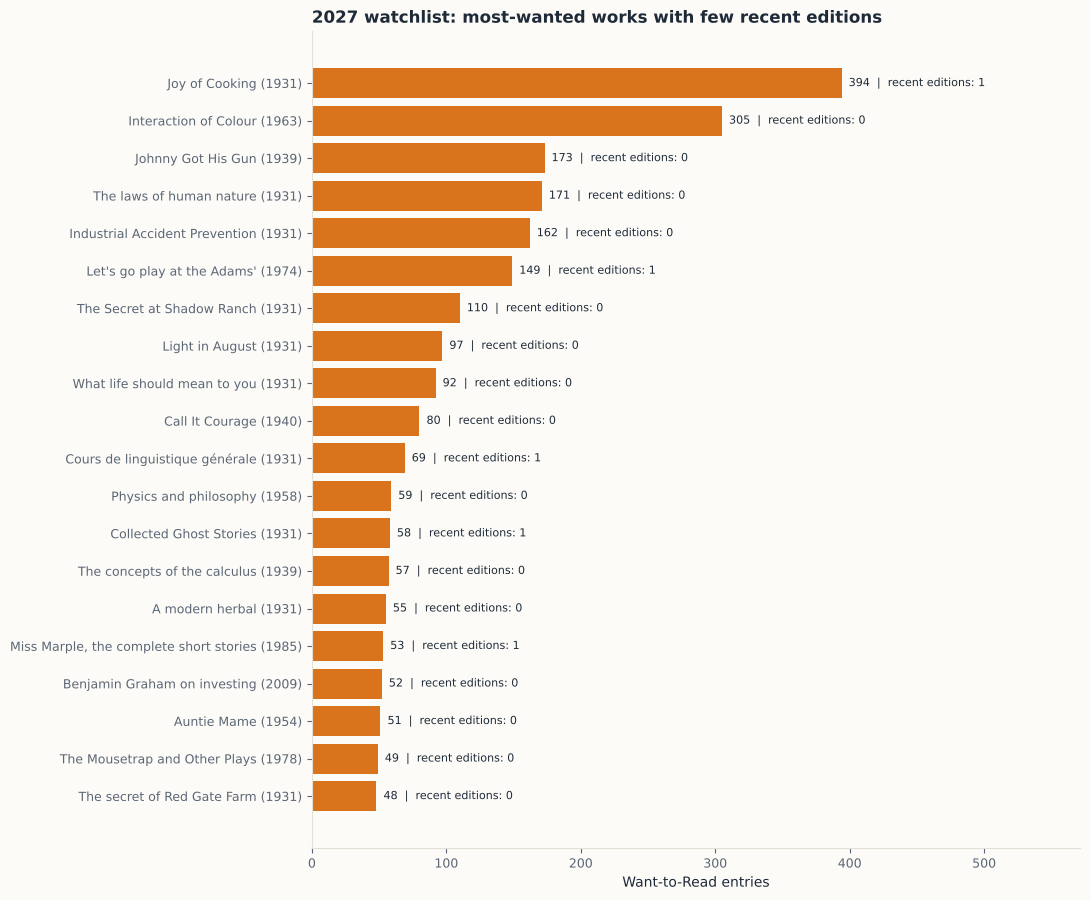

title,authors,first_year,last_death_year,want_to_read,wtr_last_12m,ratings_count,ratings_mean,n_editions,n_recent_editions,n_digitized,n_filipino_editions,gap_after_death
Joy of Cooking,"Irma S. Rombauer, Marion Rombauer Becker, Ethan Becker, John Becker, Megan Scott",1931,1962,394,31,14,4.79,67,1,16,0,False
Interaction of Colour,Joseph Albers,1963,1976,305,15,7,4.43,21,0,3,0,False
Johnny Got His Gun,Dalton Trumbo,1939,1976,173,24,16,3.81,42,0,8,0,False
The laws of human nature,"Wheeler, Raymond Holder",1931,1962,171,82,4,4.25,2,0,2,0,False
Industrial Accident Prevention,Herbert William Heinrich,1931,-,162,9,12,3.67,5,0,1,0,False
Let's go play at the Adams',Mendal W. Johnson,1974,1976,149,5,4,4.00,7,1,2,0,False
The Secret at Shadow Ranch,Leslie McFarlane,1931,1977,110,36,9,4.22,41,0,22,0,False
Light in August,William Faulkner,1931,1962,97,11,10,3.10,73,0,17,0,False
What life should mean to you,Alfred Adler,1931,1937,92,12,2,5.00,13,0,3,0,False
Call It Courage,Armstrong Sperry,1940,1976,80,4,4,4.00,51,0,16,0,False


name,works,want_to_read,works_without_recent_edition,via_us_1931,via_ph_1976
Agatha Christie,"1,012","22,008",804,2,"1,012"
Benjamin Graham,28,"4,389",22,0,28
Martin Heidegger,722,605,701,0,722
Paul Gallico,84,410,78,0,84
Marion Rombauer Becker,1,394,0,1,0
Irma S. Rombauer,1,394,0,1,0
Megan Scott,1,394,0,1,0
Ethan Becker,1,394,0,1,0
John Becker,1,394,0,1,0
Virginia Woolf,3,332,2,3,0


In [16]:
breakdown = helper.entering_2027_breakdown(profile)
show(breakdown, "Works entering the public domain on 1 January 2027")
fig = helper.plot_watchlist(watchlist, top_n=20)
plt.show()
show(watchlist[["title", "authors", "first_year", "last_death_year",
                "want_to_read", "wtr_last_12m", "ratings_count",
                "ratings_mean", "n_editions", "n_recent_editions",
                "n_digitized", "n_filipino_editions", "gap_after_death"]],
     "Top 25 of the 2027 watchlist", rows=25)
entering_authors = helper.top_authors(profile, tables["authors"],
                                      "enters_2027", top_n=15)
show(entering_authors.drop(columns="author_key"),
     "Authors with the most Want-to-Read entries among 2027 entrants",
     rows=15)

**Reading the watchlist.** Each row is a lead, and checking the top
entries against standard bibliographies shows why it must be verified:

* ***Joy of Cooking*** (Irma S. Rombauer, 1931) is the most-wanted
  entrant. Only the **original 1931 text** enters the US public domain;
  the many later revisions by her co-authors remain protected.
* ***Interaction of Colour***, ***Johnny Got His Gun***, ***Call It
  Courage***, Heisenberg's ***Physics and Philosophy*** and
  ***Auntie Mame*** enter through the Philippine rule. Their authors
  (Albers, Trumbo, Sperry, Heisenberg, Patrick Dennis) all died in 1976.
  In the US these works are either protected or depend on an unchecked
  renewal.
* ***Light in August*** is a **false positive**. Open Library's earliest
  edition is dated 1931, but the novel was published in 1932, so it
  enters the US public domain in 2028. ***Cours de linguistique
  générale*** (1916) is the reverse case: it is listed as 1931 but is
  already free.
* ***The laws of human nature*** (R. H. Wheeler, 1931) gained 82 of its
  171 entries in the last year. That pattern suggests readers confusing it
  with Robert Greene's 2018 bestseller of almost the same title, so its
  demand is probably overstated.
* ***Savage Surrender*** (credited to Pamela Clare, died 1976 according
  to the catalogue) appears to merge two different authors and needs
  checking before any decision.

The table of authors shows how concentrated the 2027 opportunity is.
**Agatha Christie alone accounts for 1,012 entering works and 22,008
Want-to-Read entries**, more than every other entrant combined. In the
Philippines all of her works become free on 1 January 2027. Elsewhere
most stay protected much longer: until 2047 under life + 70, and in the
US for 95 years from publication (only her books published in 1931 or
earlier are free there). Other 1976 deaths with
sizeable catalogues are Benjamin Graham (28 works), Martin Heidegger
(722), Paul Gallico (84), Josef Albers (81), Lin Yutang (441) and
Samuel Eliot Morison (393). Almost all of their works lack recent
editions in the catalogue, and none of Christie's has a Filipino
edition.

**Sensitivity.** The cut-offs change the size of the list but not its
top. Relaxing the demand threshold to the 95th percentile (9 entries)
gives 283 works, and to the 90th percentile (5 entries) gives 625.
Allowing up to five recent editions adds only 27 works at the 99th
percentile (53 to 80). The low-supply condition is not the binding
constraint, because almost no 2027 entrant has been reissued recently.

In [17]:
sensitivity = helper.watchlist_sensitivity(profile).reset_index()
sensitivity["WTR quantile"] = sensitivity["WTR quantile"].map("{:.0%}".format)
show(sensitivity,
     "Watchlist size under other cut-offs (columns: max recent editions)",
     floats=0)

WTR quantile,WTR threshold,0,1,2,5
90%,5,583,625,643,690
95%,9,255,283,294,332
99%,33,42,53,56,80


### 5.5 Works that are potentially public domain already

The second deliverable lists works that are **potentially public domain
already**, with the same demand threshold (at least 33 Want-to-Read
entries); 2,352 works qualify. The most wanted of them are dominated by
works that are free **only under the Philippine rule** (US status
"renewal": published 1932-1963): *Think and Grow Rich* (Napoleon Hill,
died 1970, 16,158 entries), *How to Win Friends and Influence People*
(Dale Carnegie, died 1955), *The Hobbit* and *The Lord of the Rings*
(Tolkien, died 1973), *Animal Farm* (Orwell, died 1950), *Le Petit
Prince* (Saint-Exupéry, died 1944) and *No Longer Human* (Dazai, died
1948). Most of these already have dozens of recent editions, so they are
crowded markets. The second table applies the low-supply filter as well.

In [18]:
show(pd_list[["title", "authors", "first_year", "last_death_year",
              "us_code", "ph_code", "want_to_read", "n_recent_editions",
              "n_recent_publishers", "n_digitized",
              "n_filipino_editions", "gap_after_death"]],
     "Most-wanted works estimated to be public domain", rows=25)
pd_low_supply = helper.build_pd_list(
    profile, min_want_to_read=min_wtr, top_n=50, authors=tables["authors"],
    max_recent_editions=MAX_RECENT_EDITIONS)
show(pd_low_supply[["title", "authors", "first_year", "last_death_year",
                    "us_code", "ph_code", "want_to_read", "wtr_last_12m",
                    "n_editions", "n_recent_editions", "n_digitized",
                    "gap_after_death"]],
     "High demand, at most one edition since 2017", rows=20)
show(helper.list_flag_summary(profile, min_wtr),
     "Listed works whose author link needs checking (gap_after_death)")
ph_authors = helper.philippine_authors_summary(profile)
show(ph_authors[["PH status", "works", "total_wtr",
                 "with_filipino_edition"]],
     "Works by authors with Philippine citizenship (Wikidata)")

title,authors,first_year,last_death_year,us_code,ph_code,want_to_read,n_recent_editions,n_recent_publishers,n_digitized,n_filipino_editions,gap_after_death
Think and Grow Rich,Napoleon Hill,1937,1970,renewal,pd,"16,158",93,57,55,0,False
How to Win Friends and Influence People,Dale Carnegie,1936,1955,renewal,pd,"13,484",40,26,49,0,False
Pride and Prejudice,Jane Austen,1813,1817,pd,pd,"6,756","2,290",176,289,0,False
The Art of War,孙武 (Sun Tzu),1900,-470,pd,pd,"5,473",807,118,54,0,True
人間失格,太宰 治,1948,1948,renewal,pd,"4,106",18,11,1,0,False
The Hobbit,J.R.R. Tolkien,1937,1973,renewal,pd,"4,068",52,22,86,0,False
Le petit prince,Antoine de Saint-Exupéry,1943,1944,renewal,pd,"4,028",235,94,39,1,False
Animal Farm,George Orwell,1945,1950,renewal,pd,"4,014",365,70,41,0,False
Metamorphosis,Franz Kafka,1915,1924,pd,pd,"3,648",535,78,26,0,False
The Richest Man in Babylon,George S. Clason,1926,1957,pd,pd,"3,410",128,58,21,0,False


title,authors,first_year,last_death_year,us_code,ph_code,want_to_read,wtr_last_12m,n_editions,n_recent_editions,n_digitized,gap_after_death
Games People Play,Eric Berne,1964,1970,protected_pre78,pd,"1,881",284,57,0,8,False
Madilog,Tan Malaka,1951,1949,renewal,pd,"1,084",217,4,0,0,False
Las 48 leyes del poder,Robert Greene,1998,1592,protected_post78,pd,"1,021",82,3,0,0,True
Alice in Wonderland in Five Acts,Lewis Carroll,1897,1898,pd,pd,873,8,1,0,1,False
Outwitting the devil,Napoleon Hill,2011,1970,protected_post78,pd,825,149,5,0,1,False
Picasso,"Pablo Picasso, Jean-Louis Andral, Pierre Daix",1926,1973,pd,unknown_death,812,58,240,0,5,False
The Chronicles of Narnia,C. S. Lewis,1970,1963,protected_pre78,pd,764,120,60,1,4,False
The Wealth of Nations,Adam Smith,1776,1790,pd,pd,697,66,124,0,38,False
La Poetica,Aristotle,1479,-322,pd,pd,692,106,498,0,79,True
Anatomy,"Henry Gray F.R.S., Henry Vandyke Carter",1858,1897,pd,pd,683,61,109,0,41,False


list,works,gap_after_death,gap_pct
"potentially public domain, high demand","2,352",268,11.40
... and at most one recent edition,"1,245",179,14.40
"enters 2027, high demand",146,1,0.70


PH status,works,total_wtr,with_filipino_edition
Public domain (last author died 1975 or earlier),513,"1,418",64
Unknown (an author's death year is missing),345,"2,427",32
Protected (last author died 1977 or later),328,"1,393",25
Enters public domain 1 Jan 2027 (last author died 1976),4,0,1


The **low-supply view** (1,245 works) surfaces less obvious leads: Eric
Berne's *Games People Play* (1,881 entries, no edition since 2017; free
in the Philippines since Berne died in 1970), Tan Malaka's *Madilog*
(1,084 entries) and several C. S. Lewis titles (died 1963). It also
shows the two main failure modes of the estimates:

* **Wrong author link.** *Las 48 leyes del poder* (Robert Greene, 1998)
  appears because its author record carries the death year of the
  Elizabethan writer Robert Greene (1592). It is a false positive, and it
  is marked by `gap_after_death`. This warning fires on 11.4% of the
  high-demand public-domain list and 14.4% of its low-supply subset, but on
  only 1 of the 146 high-demand 2027 entrants. Every flagged row needs
  its author checked before use.
* **Duplicate work records.** Classics such as *The Wealth of Nations* or
  *Paradise Lost* show hundreds of editions but none since 2017. Open
  Library often splits one title across several work records, and recent
  editions attached to a duplicate are not counted, so "low supply"
  is least reliable for very famous titles.

Finally, only **78 authors** in the Wikidata dump are marked as Philippine
citizens. Their 1,190 catalogued works include 513 already free in the
Philippines, but they carry few reading-log entries. Philippine authors
are under-represented in both Wikidata links and Open Library activity,
so this analysis cannot yet measure local demand for local classics.

### 5.6 Limitations

* **Missing and wrong death years.** Only 3.7% of authors have a death
  year, so 84% of works are "unknown" under the life-based rule. Where Open
  Library and Wikidata both give a year they agree for 98.8% of authors
  (within one year), and only 75 authors would change Philippine status
  depending on the source. Errors therefore come mainly from *wrong
  links* between works and authors, which no single-source check can
  detect.
* **Publication years.** First years come from the earliest catalogued
  edition. They can be too early (a misdated edition, as with *Light in
  August*), too late (old editions missing, 950,690 works), or
  placeholders (the 1900 and 1800 spikes).
* **US renewals.** The 3.0 million works first published 1932-1963 cannot
  be classified without US Copyright Office renewal records, which are
  not in the dumps. We also ignore special US cases: works by US
  government authors (always public domain), works published without a
  copyright notice before 1978, and foreign works whose US copyright was
  restored in 1996.
* **Philippine law.** We apply only the general life + 50 rule (RA 8293
  sec. 213-214). We do not model works of corporate or anonymous authorship,
  works published after the author's death, or the separate rights of
  translators and editors. A new translation must start from a source
  text that is itself free.
* **Work-level counts.** A "work" bundles all its editions and
  translations. Revised editions (*Joy of Cooking*) and compilations
  (Christie omnibus volumes) add new material that may still be protected.
  Duplicate work records split editions and understate supply.
* **Demand.** Reading-log and rating activity reflects Open Library users
  only, who are not representative of all readers (and certainly not of
  Philippine readers). The dump keeps only entries still on a shelf,
  undercounting older months, and the October 2024 outage depresses one
  month.
* **Scope.** The analysis is descriptive. The thresholds (99th percentile
  of demand, at most one recent edition) are judgement calls whose effect
  we report in Section 5.4, and no estimate here is legal advice.

### 5.7 Recommendations

1. **Act on the Philippine 2027 opportunity first.** The clearest lead is
   the Agatha Christie catalogue, which enters the public domain in the
   Philippines on 1 January 2027 with substantial demand and no Filipino
   editions. Working from the original English texts (not later
   translations or revised compilations), a Philippine publisher could
   prepare Tagalog or Filipino translations of the most-wanted titles,
   after legal confirmation of the date of death and of the local term.
2. **Verify each watchlist row before acting.** Check the first edition
   against a national bibliography (this catches cases such as *Light in
   August*), confirm the author's identity and death date, and inspect
   any row marked `gap_after_death`. The 53-work list is short enough to
   check by hand in a few days.
3. **Resolve the 1932-1963 renewal question.** Matching these 3.0 million
   works against digitized US renewal records, for example Stanford's
   Copyright Renewal Database of books from 1923-1963, would turn the
   largest "uncertain" group into firm answers. That is the most valuable
   extension of this pipeline.
4. **Improve author dates at the source.** Because the Philippine estimate
   is limited mainly by missing death years and mislinked authors,
   adding Wikidata links to the most-shelved Open Library authors (and
   fixing the conflations found here) would raise coverage for everyone
   using the data.
5. **Re-run monthly.** The pipeline reuses its Parquet tables, so each new
   dump can refresh the lists in about an hour. In late 2027 the same
   code, with `REFERENCE_DATE` set to 2028, produces the next year's
   watchlist (works from 1932 and deaths in 1977).

## References

Apache Software Foundation. (2025). *PySpark documentation* (Version 4.0). https://spark.apache.org/docs/latest/api/python/

Copyright Act of 1976, 17 U.S.C. §§ 302–304 (1976).

Hirtle, P. B. (2026). *Copyright term and the public domain in the United States*. Cornell University Library. https://guides.library.cornell.edu/copyright/publicdomain

Intellectual Property Code of the Philippines, Rep. Act No. 8293 (1997).

Open Library. (2026). *Open Library data dumps, 31 October 2026* [Data set]. Internet Archive. https://openlibrary.org/developers/dumps

Stanford University Libraries. (n.d.). *Copyright renewal database*. https://exhibits.stanford.edu/copyrightrenewals

U.S. Copyright Office. (n.d.). *Duration of copyright: Provisions of the law dealing with the length of copyright protection* (Circular 15A). https://www.copyright.gov/circs/circ15a.pdf

Wikidata contributors. (2026). *Wikidata* [Data set]. Wikimedia Foundation. https://www.wikidata.org

Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker, S., & Stoica, I. (2016). Apache Spark: A unified engine for big data processing. *Communications of the ACM, 59*(11), 56–65. https://doi.org/10.1145/2934664

In [19]:
spark.stop()